# Task 3: Reinforcement Learning

## Setup Code / Packages (Google Colab, GPU)
1. *Runtime → Change runtime type → **T4 GPU***.
2. Run the setup cell. It connects Google Drive, downloads the team's repo, re-applies our Task 1–3 scene changes, and installs **pinned** package versions (the same ones tested locally).
3. Outputs (checkpoints, video, metrics) are saved to the `tritondroid/task3` folder in Google Drive.

**Pinned versions and why:** `brax==0.12.5` with `mujoco/mujoco-mjx==3.3.4` and `jax==0.4.35`. The team's `environment.yml` pins `brax==0.12.1`, which isn't compatible with MJX 3.3.4 (`Data.__init__() got an unexpected keyword argument 'contact'`); 0.12.5 is the first Brax release after MJX 3.3.4.


In [1]:
# --- Colab setup: run first (~3-4 minutes) ---
import os, sys, subprocess, shutil

from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/tritondroid"
WORK_DIR = os.path.join(DRIVE_DIR, "task3")            # outputs are saved here
os.makedirs(WORK_DIR, exist_ok=True)

# Team repo (meshes etc.) on Colab's local disk
SIM_ROOT = "/content/simulation"
if not os.path.exists(SIM_ROOT):
    subprocess.run(["git", "clone", "--depth", "1", "-b", "ml_onboarding",
                    "https://github.com/triton-droids/simulation.git", SIM_ROOT], check=True)

def apply_scene_changes(sim_root, scene_xml_text):
    """Recreate our Task 1-3 scene changes on a fresh clone of the team's repo."""
    d = os.path.join(sim_root, "assets/descriptions")

    def patch(path, edits):
        text = open(path).read()
        for old, new in edits:
            assert text.count(old) == 1, f"{os.path.basename(path)}: expected exactly one match for {old[:50]!r}"
            text = text.replace(old, new)
        return text

    # Task 1: the scene (from Drive) and the tool-center-point body between the fingertips
    open(os.path.join(d, "DropCubeInBinEnv.xml"), "w").write(scene_xml_text)
    body = os.path.join(d, "panda/mjcf/panda_body.xml")
    if "panda_hand_tcp" not in open(body).read():
        anchor = '<geom mesh="hand_c" class="collision"/>'
        patched = patch(body, [(anchor, anchor +
            '\n                      <!-- Tool center point: midpoint between the fingertips -->'
            '\n                      <body name="panda_hand_tcp" pos="0 0 0.1034"/>')])
        open(body, "w").write(patched)   # read+patch first, then write (opening with "w" empties the file)

    # Task 2 fix: a stronger gripper (same open/closed positions); the original ~2 N squeeze let the cube slip
    grip_edits = [(
        '    <general class="panda" name="actuator8" tendon="split" forcerange="-100 100" ctrlrange="0 255"\n'
        '      gainprm="0.01568627451 0 0" biasprm="0 -100 -10"/>',
        '    <!-- Gains scaled x10 (same open/closed positions): at the original strength the grip\n'
        '         squeezed with ~2 N and the cube slid out of the fingers. -->\n'
        '    <general class="panda" name="actuator8" tendon="split" forcerange="-200 200" ctrlrange="0 255"\n'
        '      gainprm="0.1568627451 0 0" biasprm="0 -1000 -100"/>')]
    # Task 3: light-collision robot for MJX. Arm meshes don't collide; only the fingertip pad boxes do.
    mjx_edits = grip_edits + [(
        '<default class="collision">\n        <geom type="mesh" group="3"/>',
        '<default class="collision">\n        <geom type="mesh" group="3" contype="0" conaffinity="0"/>  '
        '<!-- MJX variant: arm meshes do NOT collide (too expensive on GPU) -->')]
    for k in range(1, 6):
        pat = f'<default class="fingertip_pad_collision_{k}">\n          <geom type="box"'
        mjx_edits.append((pat, pat + ' contype="1" conaffinity="1"'))
    asset = os.path.join(d, "panda/mjcf/panda_asset.xml")
    header = ("<!-- AUTO-GENERATED from panda_asset.xml for Task 3 (MJX). Identical except: arm collision meshes are\n"
              "     disabled and only the fingertip pad boxes collide, which keeps GPU physics fast. -->\n")
    open(os.path.join(d, "panda/mjcf/panda_asset_mjx.xml"), "w").write(header + patch(asset, mjx_edits))

    scene_mjx = scene_xml_text.replace(
        '<include file="panda/mjcf/panda_asset.xml"/>',
        '<include file="panda/mjcf/panda_asset_mjx.xml"/>  <!-- light collision version for MJX (Task 3) -->')
    scene_mjx = scene_mjx.replace(
        '<mujoco model="cube in bin scene">',
        '<!-- Task 3 (MJX) copy of DropCubeInBinEnv.xml: same scene, light collision robot file. -->\n<mujoco model="cube in bin scene">')
    assert "panda_asset_mjx.xml" in scene_mjx
    open(os.path.join(d, "DropCubeInBinEnv_mjx.xml"), "w").write(scene_mjx)

apply_scene_changes(SIM_ROOT, open(os.path.join(DRIVE_DIR, "DropCubeInBinEnv.xml")).read())

# Same versions as tested locally (see the markdown above). The CUDA plugin is listed explicitly:
# "jax[cuda12]==0.4.35" would silently pull jaxlib 0.4.34 instead of the tested 0.4.35.
pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                      "numpy==2.2.6", "jax==0.4.35", "jaxlib==0.4.35",
                      "jax-cuda12-plugin[with_cuda]==0.4.35", "jax-cuda12-pjrt==0.4.35", "nvidia-cuda-nvcc-cu12==12.6.85",
                      "mujoco==3.3.4", "mujoco-mjx==3.3.4", "brax==0.12.5", "flax==0.10.4",
                      "optax==0.2.5", "chex==0.1.90", "orbax-checkpoint==0.11.5", "mediapy"],
                     capture_output=True, text=True)
if pip.returncode != 0:
    print(pip.stdout[-3000:], pip.stderr[-3000:])
    raise RuntimeError("pip install failed (details above)")

# If Colab had already loaded a different numpy, the new one only takes effect after a restart.
from importlib.metadata import version
if "numpy" in sys.modules and sys.modules["numpy"].__version__ != version("numpy"):
    raise SystemExit("Packages installed. Now do Runtime -> Restart session, then Runtime -> Run all again.")
os.chdir(WORK_DIR)
print("setup done | working dir:", os.getcwd())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
setup done | working dir: /content/drive/MyDrive/tritondroid/task3


In [2]:
# Configure MuJoCo for Colab and check the GPU is visible to JAX
import os
os.environ['MUJOCO_GL'] = 'egl'  # enables headless rendering
os.environ['WANDB_MODE'] = 'offline'   # log locally; no W&B account needed
import jax
print("JAX devices:", jax.devices())
assert jax.devices()[0].platform == "gpu", "No GPU: Runtime -> Change runtime type -> T4 GPU"


ERROR:jax._src.xla_bridge:Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 610, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda13/__init__.py", line 373, in initialize
    c_api = xb.register_plugin(
        'cuda', priority=500, library_path=str(path), options=options
    )
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 705, in register_plugin
    c_api = xla_client.load_pjrt_plugin_dynamically(plugin_name, library_path)
  File "/usr/local/lib/python3.13/dist-packages/jaxlib/xla_client.py", line 160, in load_pjrt_plugin_dynamically
    return _xla.load_pjrt_plugin(plugin_name, library_path, c_api=None)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
jaxlib.xla_extension.Xl

JAX devices: [CudaDevice(id=0)]


## Part 1: Implementing the Pick-and-Place MJX Environment

In this part, you will implement the `PickAndPlace` environment using MuJoCo and MJX.

- `_init_env`: Initialize important environment variables such as the robot’s home pose, cube and bin locations, and body/joint IDs.
- `reset`: Reset the simulation state with randomized initial positions for the robot arm, cube, and bin.
- `step`: Advance the simulation forward given an action. Update environment state, check if the cube has been grasped, compute the reward, and determine if the episode has ended.
- `_get_obs`: Define the observation space.
- `check_grasp`: Determine whether the cube is grasped by the robot.
- `check_success`: Define the success condition by checking if the cube is inside the bin boundaries.
- `_compute_reward`: Design a shaped reward that encourages approaching the cube, grasping it, and successfully placing it into the bin.
**Implementation notes (adjustments and why):**
- **Light-collision scene** (`DropCubeInBinEnv_mjx.xml`): with the arm's collision meshes enabled, MJX needed 1,928 contact slots and ~344 ms per step (CPU). With only the fingertip pads, cube, table, bin and floor colliding: 668 slots and ~3 ms per step. The pads alone still grasp reliably (the Task 2 expert succeeds 10/10 on this scene).
- **Body positions read from `xpos`:** Brax's `x` leaves out the world body, so indexing it by MuJoCo body id (`x.pos[body_id]`) returns the *next* body (e.g. the bin's position for the cube). `xpos` is indexed by MuJoCo body id directly.
- **TCP name:** `panda_hand_tcp` (the point between the fingertips), not `panda_hand`.
- **Actions:** PPO outputs values in [-1, 1]. Sending those directly as motor commands would pin every joint near 0 rad and keep the gripper almost closed, so arm actions are *changes* in joint target (≤ 0.04 rad per step) and the gripper action maps to 0–255.
- **`done` dtype:** `reset` returned a bool but `step` a float, which breaks PPO's `jax.lax.scan`; both are float now.
- **Success doesn't end the episode:** shaping rewards are paid every step, so ending at success would make hovering near the bin pay more than finishing. Success is rewarded every step instead.


In [3]:
from brax.envs.base import PipelineEnv, State
from mujoco.mjx._src import support
from brax.io import mjcf
from jax import numpy as jp
from typing import Any
import mujoco
import jax
import os

# Light-collision copy of the Task 1 scene: only the fingertip pads, cube, table, bin and floor collide.
# The full arm collision meshes make MJX ~100x slower (see the note in the setup section).
XML_PATH = os.path.join(SIM_ROOT, "assets/descriptions/DropCubeInBinEnv_mjx.xml")

# Bin geometry (bin_body.xml): inner walls at +-0.045 m, wall tops 0.055 m above the bin origin
BIN_INNER_HALF = 0.045
BIN_WALL_TOP = 0.055


class PickAndPlace(PipelineEnv):
    def __init__(self, xml_path: str, cfg, **kwargs: Any):
        # DO NOT MODIFY
        mj_model = mujoco.MjModel.from_xml_path(xml_path)

        sys = mjcf.load_model(mj_model)
        sys = sys.tree_replace(
            {
                "opt.timestep": cfg.sim.timestep,
                "opt.solver": cfg.sim.solver,
                "opt.iterations": cfg.sim.iterations,
                "opt.ls_iterations": cfg.sim.ls_iterations,
            }
        )
        kwargs["n_frames"] = cfg.action.n_frames
        kwargs["backend"] = "mjx"

        super().__init__(sys, **kwargs)

        self.max_steps = 500
        self._init_env()

    def _safe_body_id(self, name: str):
        try:
            return support.name2id(self.sys, mujoco.mjtObj.mjOBJ_BODY, name)
        except Exception:
            return None

    def _init_env(self) -> None:
        mj = self.sys.mj_model
        self.init_q = jp.array(mj.keyframe("home").qpos)
        self.init_ctrl = jp.array(mj.keyframe("home").ctrl)

        self.nu = self.sys.nu
        self.nq = self.sys.nq
        self.nv = self.sys.nv

        # Body names from Task 1. The TCP is the point between the fingertips ("panda_hand_tcp"),
        # not the hand's base ("panda_hand" doesn't exist in our scene).
        self.tcp_body_id = self._safe_body_id("panda_hand_tcp")
        self.cube_body_id = self._safe_body_id("cube")
        self.bin_body_id = self._safe_body_id("bin")
        assert None not in (self.tcp_body_id, self.cube_body_id, self.bin_body_id), "body names don't match the XML"

        # Geoms used for the contact-based grasp check
        self.cube_geom_id = mj.geom("cube_geom").id
        left, right = mj.body("left_finger").id, mj.body("right_finger").id
        colliding = lambda b: [g for g in range(mj.ngeom) if mj.geom_bodyid[g] == b and mj.geom_contype[g] > 0]
        self.left_pad_ids = jp.array(colliding(left))
        self.right_pad_ids = jp.array(colliding(right))

        # Action mapping. PPO outputs values in [-1, 1]:
        #   arm (7): change in joint target per step, scaled to at most 0.04 rad
        #   gripper (1): mapped to the 0 (closed) .. 255 (open) command range
        self.action_scale = 0.04
        self.arm_lower = jp.array(mj.actuator_ctrlrange[:7, 0])
        self.arm_upper = jp.array(mj.actuator_ctrlrange[:7, 1])
        self.cube_xy_range = 0.05

    def _body_pos(self, pipeline_state: State, body_id):
        if body_id is None:
            return jp.zeros(3)
        # xpos is indexed by MuJoCo body id. (The template used x.pos, but Brax's x leaves out the
        # world body, so x.pos[body_id] returned the NEXT body's position, e.g. the bin for the cube.)
        return pipeline_state.xpos[body_id]

    def reset(self, rng: jp.ndarray) -> State:
        rng, cube_key, arm_key = jax.random.split(rng, 3)
        qpos = self.init_q.copy()
        qvel = jp.zeros(self.nv)

        # Randomize the cube within +-5 cm of its default spot, and add small noise to the arm joints.
        # (The bin has no joint in the scene, so its position stays fixed.)
        qpos = qpos.at[9:11].add(jax.random.uniform(cube_key, (2,), minval=-self.cube_xy_range, maxval=self.cube_xy_range))
        qpos = qpos.at[:7].add(jax.random.uniform(arm_key, (7,), minval=-0.02, maxval=0.02))
        # Position actuators hold whatever ctrl says, so start ctrl at the (noisy) start pose, gripper open.
        ctrl = jp.concatenate([qpos[:7], jp.array([255.0])])
        pipeline_state = self.pipeline_init(qpos, qvel, ctrl=ctrl)

        cube_pos = self._body_pos(pipeline_state, self.cube_body_id)
        state_info = {
            "rng": rng,
            "step": jp.array(0),
            "done": jp.array(False),
            "success": jp.array(False),
            "is_grasped": jp.array(False),
            "cube_init_z": cube_pos[2],
        }

        obs = self._get_obs(pipeline_state, state_info)
        reward = jp.array(0.0)
        done = jp.array(0.0)   # float, same type as step() returns (PPO's jax.lax.scan needs matching types)
        metrics = {
            "reward": reward,
            "is_grasped": jp.array(0.0),
            "success": jp.array(0.0),
            "tcp_cube_dist": jp.linalg.norm(self._body_pos(pipeline_state, self.tcp_body_id) - cube_pos),
            "cube_lift": jp.array(0.0),
        }

        return State(pipeline_state, obs, reward, done, metrics, state_info)

    def step(self, state: State, action: jp.ndarray) -> State:
        # Convert the policy's [-1, 1] action into motor commands (see _init_env).
        prev_ctrl = state.pipeline_state.ctrl
        arm = jp.clip(prev_ctrl[:7] + self.action_scale * action[:7], self.arm_lower, self.arm_upper)
        gripper = (jp.clip(action[7], -1.0, 1.0) + 1.0) * 127.5
        ctrl = jp.concatenate([arm, gripper[None]])
        pipeline_state = self.pipeline_step(state.pipeline_state, ctrl)

        is_grasped = self.check_grasp(pipeline_state)
        success = self.check_success(pipeline_state) & ~is_grasped   # must be released into the bin

        state.info["is_grasped"] = is_grasped
        state.info["success"] = success

        reward = self._compute_reward(pipeline_state, state.info, action)
        obs = self._get_obs(pipeline_state, state.info)

        state.info["step"] += 1
        state.info["step"] = jp.where(state.info["step"] > self.max_steps, 0, state.info["step"])

        # Episode ends only on the step limit. Success is rewarded every step instead of ending the
        # episode: otherwise hovering near the bin (collecting shaping rewards) would pay more than finishing.
        done = state.info["step"] == 0
        state.info["done"] = done

        tcp_pos = self._body_pos(pipeline_state, self.tcp_body_id)
        cube_pos = self._body_pos(pipeline_state, self.cube_body_id)
        state.metrics["reward"] = reward
        state.metrics["is_grasped"] = is_grasped.astype(jp.float32)
        state.metrics["success"] = success.astype(jp.float32)
        state.metrics["tcp_cube_dist"] = jp.linalg.norm(tcp_pos - cube_pos)
        state.metrics["cube_lift"] = jp.maximum(cube_pos[2] - state.info["cube_init_z"], 0.0)

        return state.replace(
            pipeline_state=pipeline_state,
            obs=obs,
            reward=reward,
            done=done.astype(jp.float32),
        )

    def _get_obs(
        self,
        pipeline_state: State,
        info: dict[str, Any],
    ):
        qpos = pipeline_state.q
        qvel = pipeline_state.qd

        tcp_pos = self._body_pos(pipeline_state, self.tcp_body_id)
        cube_pos = self._body_pos(pipeline_state, self.cube_body_id)
        bin_pos = self._body_pos(pipeline_state, self.bin_body_id)

        obs = jp.concatenate(
            [
                qpos,
                qvel,
                tcp_pos,
                cube_pos,
                bin_pos,
                tcp_pos - cube_pos,
                cube_pos - bin_pos,
            ]
        )

        return {
            "state": obs,
            "privileged_state": obs,
        }

    def check_success(self, pipeline_state: State):
        cube_pos = self._body_pos(pipeline_state, self.cube_body_id)
        bin_pos = self._body_pos(pipeline_state, self.bin_body_id)

        # Cube center inside the bin's inner walls (4.5 cm half-width) and below the wall tops.
        inside_xy = jp.all(jp.abs(cube_pos[:2] - bin_pos[:2]) < BIN_INNER_HALF)
        below_rim = cube_pos[2] < bin_pos[2] + BIN_WALL_TOP
        return inside_xy & below_rim

    def check_grasp(self, pipeline_state: State):
        # Contact-based: the cube is touching a fingertip pad on BOTH fingers.
        c = pipeline_state.contact
        touching = c.dist < 1e-3

        def touches(pad_ids):
            pair = ((c.geom1 == self.cube_geom_id) & jp.isin(c.geom2, pad_ids)) | (
                (c.geom2 == self.cube_geom_id) & jp.isin(c.geom1, pad_ids))
            return jp.any(pair & touching)

        return touches(self.left_pad_ids) & touches(self.right_pad_ids)

    def _compute_reward(self, pipeline_state: State, info: dict[str, Any], action: jp.ndarray):
        tcp_pos = self._body_pos(pipeline_state, self.tcp_body_id)
        cube_pos = self._body_pos(pipeline_state, self.cube_body_id)
        bin_pos = self._body_pos(pipeline_state, self.bin_body_id)

        # Staged dense reward: each term only matters once the previous stage is reached.
        dist_tcp_cube = jp.linalg.norm(tcp_pos - cube_pos)
        reach_reward = 1.0 - jp.tanh(10.0 * dist_tcp_cube)                  # 1 when the hand is at the cube
        grasp_bonus = info["is_grasped"].astype(jp.float32)                  # both fingers on the cube
        lift = jp.clip((cube_pos[2] - info["cube_init_z"]) / 0.10, 0.0, 1.0)
        lift_reward = lift * grasp_bonus                                      # lifting only counts while grasped
        above_bin = bin_pos + jp.array([0.0, 0.0, 0.12])
        transport_reward = (1.0 - jp.tanh(5.0 * jp.linalg.norm(cube_pos - above_bin))) * (lift > 0.3)
        success_bonus = info["success"].astype(jp.float32)
        action_penalty = jp.sum(action[:7] ** 2)                              # discourage jerky motion

        reward = (
            1.0 * reach_reward
            + 1.0 * grasp_bonus
            + 2.0 * lift_reward
            + 2.0 * transport_reward
            + 10.0 * success_bonus
            - 0.01 * action_penalty
        )
        return reward


## Using Configs in the Codebase
In our codebase, we use Hydra and dataclasses to manage configurations. This keeps experiment settings (like simulation parameters, observation sizes, or agent hyperparameters) separate from the actual environment and training code, making it easy to reproduce results or run variations of the same experiment.

The `PickAndPlaceConfig` defines all the key parameters needed for this task:
- **sim**: Physics engine settings such as timestep and solver iterations.
- **action**: How actions are repeated in the environment.
- **ppo_agent**: PPO hyperparameters.
- **ppo_networks**: Neural network configuration.
- **seed**: Random seed for reproducibility.

In [4]:
from dataclasses import dataclass, field
from typing import Tuple

@dataclass
class PickAndPlaceConfig:
    """Configuration class for the MJX environment."""

    @dataclass
    class SimConfig:
        timestep: float = 0.002
        solver: int = 2
        iterations: int = 5
        ls_iterations: int = 8

    @dataclass
    class ActionConfig:
        n_frames: int = 5

    @dataclass
    class PPOAgentConfig:
        num_timesteps: int = 10_000_000   # overwritten below from the measured speed and TRAIN_MINUTES
        num_evals: int = 20
        episode_length: int = 300      # 3 s at dt = 0.01 s; the scripted expert needs ~2.5 s
        unroll_length: int = 10        # more PPO updates per env step than 50 (budget is short)
        num_minibatches: int = 32
        num_updates_per_batch: int = 4
        discounting: float = 0.97
        learning_rate: float = 3e-4
        entropy_cost: float = 0.02
        clipping_epsilon: float = 0.2
        num_envs: int = 1024
        batch_size: int = 256
        seed: int = 42
        normalize_observations: bool = True
        action_repeat: int = 1
        max_grad_norm: float = 1.0
        num_resets_per_eval: int = 1

    @dataclass
    class PPONetworksConfig:
        policy_hidden_layer_sizes: Tuple[int, ...] = (256, 256, 256)
        value_hidden_layer_sizes: Tuple[int, ...] = (256, 256, 256)
        policy_obs_key: str = "state"
        value_obs_key: str = "privileged_state"

    sim: SimConfig = field(default_factory=SimConfig)
    action: ActionConfig = field(default_factory=ActionConfig)
    ppo_agent: PPOAgentConfig = field(default_factory=PPOAgentConfig)
    ppo_networks: PPONetworksConfig = field(default_factory=PPONetworksConfig)
    seed: int = PPOAgentConfig.seed

config = PickAndPlaceConfig()
TRAIN_MINUTES = 40   # wall-clock budget for the main run (Colab T4)


Next, we create our train and evaluation environment. We define a factory function for building PPO networks with the architecture and observation settings specified in the config.

We set things up this way because we will use Brax’s PPO implementation, which expects an environment and a networks factory to run training.

In [5]:
from brax.training.agents.ppo import networks as ppo_networks
import functools

env = PickAndPlace(
        xml_path=XML_PATH,
        cfg = config,
    )

eval_env = PickAndPlace(
    xml_path=XML_PATH,
    cfg = config,
)

make_networks_factory = functools.partial(
    ppo_networks.make_ppo_networks,
    policy_hidden_layer_sizes=config.ppo_networks.policy_hidden_layer_sizes,
    value_hidden_layer_sizes=config.ppo_networks.value_hidden_layer_sizes,
    policy_obs_key=config.ppo_networks.policy_obs_key,
    value_obs_key=config.ppo_networks.value_obs_key,
)

/usr/local/lib/python3.13/dist-packages/brax/io/mjcf.py:480: UserWarning: Brax System, piplines and environments are not actively being maintained. Please see MJX for a well maintained JAX-based physics engine: https://github.com/google-deepmind/mujoco/tree/main/mjx. For a host of environments that use MJX, see: https://github.com/google-deepmind/mujoco_playground.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/brax/io/mjcf.py:480: UserWarning: Brax System, piplines and environments are not actively being maintained. Please see MJX for a well maintained JAX-based physics engine: https://github.com/google-deepmind/mujoco/tree/main/mjx. For a host of environments that use MJX, see: https://github.com/google-deepmind/mujoco_playground.
  warnings.warn(


We also define a function for saving parameters that runs every:

`num_timesteps` / `num_evals`


In [6]:
import os
from brax.io import model

def policy_params_fn(current_step: int, make_policy: Any, params: Any):
    # Save a checkpoint at every evaluation (to Drive), so a disconnect doesn't lose training.
    path = os.path.join(WORK_DIR, "checkpoints")
    os.makedirs(path, exist_ok=True)
    model.save_params(os.path.join(path, f"step_{current_step}"), params)
    model.save_params(os.path.join(path, "latest"), params)


Lastly, we set up Weights & Biases to monitor training progress and log metrics in real time and pass the algorithm parameters to the train function.


In [7]:
from brax.training.agents.ppo import train as ppo
from dataclasses import asdict
import functools
import wandb
import time

run_name = "PickandPlace"
wandb.init(
    project="OnBoarding",
    name=run_name,
    config=asdict(config.ppo_agent),
    )

history = []          # (env steps, eval metrics) for the plot below

def progress(num_steps, metrics):
    times.append(time.time())
    wandb.log(metrics, step=num_steps)
    m = {k.split("/")[-1]: float(v) for k, v in metrics.items() if k.startswith("eval/episode_") and not k.endswith("_std")}
    history.append((num_steps, m))
    L = config.ppo_agent.episode_length
    print(f"{num_steps:>10,} steps | {times[-1] - times[0]:5.0f}s | reward/ep {m['episode_reward']:8.1f} | "
          f"mean hand-cube dist {m['episode_tcp_cube_dist'] / L * 100:5.1f} cm | grasped {m['episode_is_grasped'] / L:5.1%} of steps | "
          f"success {m['episode_success'] / L:5.1%} of steps")

def make_train_fn(**overrides):
    return functools.partial(
        ppo.train,
        **{**asdict(config.ppo_agent), **overrides},
        network_factory=make_networks_factory,   # pass the configured network factory to PPO
    )

# 1) Short speed test to measure steps/second on this GPU, then size the main run to TRAIN_MINUTES.
times = [time.time()]
_ = make_train_fn(num_timesteps=1_000_000, num_evals=2)(environment=env, eval_env=eval_env, progress_fn=lambda n, m: times.append(time.time()))
jit_and_eval = times[1] - times[0]
steps_per_sec = 1_000_000 / max(times[-1] - times[1], 1e-6)
config.ppo_agent.num_timesteps = int(steps_per_sec * 60 * TRAIN_MINUTES * 0.85)   # 15% margin for evals
print(f"speed test: {steps_per_sec:,.0f} env steps/s (compile + first eval {jit_and_eval:.0f}s)"
      f" -> main run: {config.ppo_agent.num_timesteps:,} steps in ~{TRAIN_MINUTES} min")
history.clear()


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))


speed test: 1,205 env steps/s (compile + first eval 120s) -> main run: 2,457,277 steps in ~40 min


We are ready to start training!

In [8]:
times = [time.time()]
train_fn = make_train_fn()
make_inference_fn, params, _ = train_fn(
    environment=env, eval_env=eval_env, progress_fn=progress, policy_params_fn=policy_params_fn
)

print(f"time to jit: {times[1] - times[0]:.0f}s")
print(f"time to train: {times[-1] - times[1]:.0f}s")
model.save_params(os.path.join(WORK_DIR, "final_params"), params)

import json
json.dump(history, open(os.path.join(WORK_DIR, "training_history.json"), "w"))
first, last = history[0][1], history[-1][1]
L = config.ppo_agent.episode_length
for key, label in [("episode_reward", "reward per episode"), ("episode_tcp_cube_dist", "mean hand-cube distance (m)"),
                   ("episode_is_grasped", "fraction of steps grasped"), ("episode_cube_lift", "mean cube lift (m)"),
                   ("episode_success", "fraction of steps successful")]:
    scale = 1 if key == "episode_reward" else 1 / L
    print(f"{label:32s} untrained policy: {first[key] * scale:8.3f}   ->   trained: {last[key] * scale:8.3f}")


/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))


         0 steps |   110s | reward/ep     -1.2 | mean hand-cube dist  46.2 cm | grasped  0.0% of steps | success  0.0% of steps


/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))


   163,840 steps |   310s | reward/ep     28.8 | mean hand-cube dist  25.2 cm | grasped  0.1% of steps | success  0.0% of steps
   327,680 steps |   452s | reward/ep     79.7 | mean hand-cube dist  16.7 cm | grasped  0.9% of steps | success  0.0% of steps
   491,520 steps |   597s | reward/ep     97.9 | mean hand-cube dist  14.6 cm | grasped  3.3% of steps | success  0.0% of steps
   655,360 steps |   741s | reward/ep    108.0 | mean hand-cube dist  14.2 cm | grasped  3.5% of steps | success  0.0% of steps
   819,200 steps |   885s | reward/ep    120.2 | mean hand-cube dist  11.4 cm | grasped  3.1% of steps | success  0.0% of steps
   983,040 steps |  1029s | reward/ep    126.6 | mean hand-cube dist  12.0 cm | grasped  4.0% of steps | success  0.0% of steps
 1,146,880 steps |  1174s | reward/ep    144.8 | mean hand-cube dist  11.1 cm | grasped  6.0% of steps | success  0.0% of steps
 1,310,720 steps |  1319s | reward/ep    174.7 | mean hand-cube dist  10.2 cm | grasped 11.2% of steps |

## Visualize Rollouts

In [9]:
import jax

jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)
jit_inference_fn = jax.jit(make_inference_fn(params, deterministic=True))

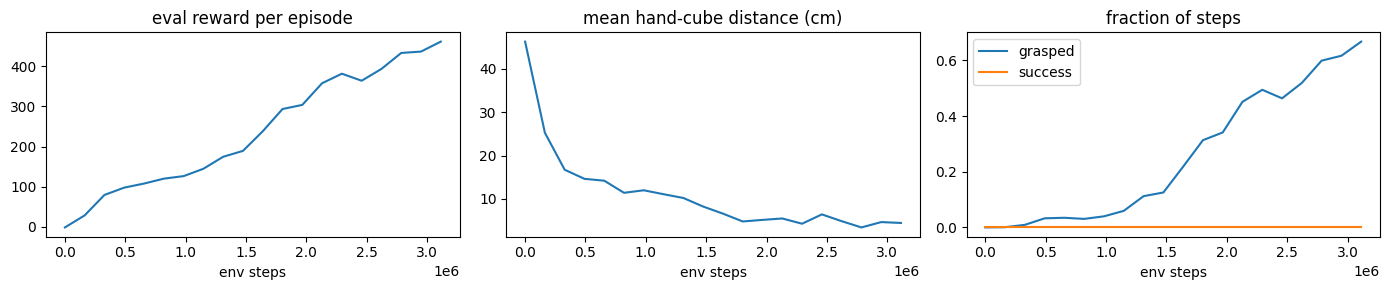

/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/xla.py:133: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))


This browser does not support the video tag.


In [10]:
import mediapy as media
import matplotlib.pyplot as plt
import numpy as np

# Training curves
steps = [h[0] for h in history]
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
ax[0].plot(steps, [h[1]["episode_reward"] for h in history]); ax[0].set_title("eval reward per episode")
ax[1].plot(steps, [h[1]["episode_tcp_cube_dist"] / L * 100 for h in history]); ax[1].set_title("mean hand-cube distance (cm)")
ax[2].plot(steps, [h[1]["episode_is_grasped"] / L for h in history], label="grasped")
ax[2].plot(steps, [h[1]["episode_success"] / L for h in history], label="success"); ax[2].legend(); ax[2].set_title("fraction of steps")
for a in ax: a.set_xlabel("env steps")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "training_curves.png")); plt.show()

# Rollout video of the trained (deterministic) policy
rng = jax.random.PRNGKey(42)
rollout = []
n_episodes = 1

for _ in range(n_episodes):
  state = jit_reset(rng)
  rollout.append(state.pipeline_state)
  for i in range(config.ppo_agent.episode_length):
    act_rng, rng = jax.random.split(rng)
    ctrl, _ = jit_inference_fn(state.obs, act_rng)
    state = jit_step(state, ctrl)
    rollout.append(state.pipeline_state)   # render() expects physics states, not env States

render_every = 2
frames = env.render(rollout[::render_every], camera="fixed")
try:   # use the ffmpeg bundled with imageio-ffmpeg if there's no system ffmpeg
    import imageio_ffmpeg; media.set_ffmpeg(imageio_ffmpeg.get_ffmpeg_exe())
except ImportError:
    pass
media.write_video(os.path.join(WORK_DIR, "ppo_rollout.mp4"), frames, fps=1.0 / env.dt / render_every)
media.show_video(frames, fps=1.0 / env.dt / render_every)


## Reward design: what each term does

The reward is a weighted sum of **staged** terms. Each stage only pays once the previous one is achieved, so the agent is pulled step by step through reach → grasp → lift → carry → release.

| Term | Weight | Formula | Behavior it encourages |
|---|---|---|---|
| Reach | 1.0 | `1 - tanh(10 · ‖hand − cube‖)` | Move the hand to the cube. Close to 1 within a few cm, so it saturates once the hand is there and stops dominating. |
| Grasp | 1.0 | 1 if a fingertip pad on **both** fingers touches the cube (MJX contact list) | Close the gripper on the cube, not just near it. Contact-based, so hovering doesn't count. |
| Lift | 2.0 | `clip(cube height gain / 10 cm, 0, 1)` × grasp | Pick the cube up. Multiplied by grasp so knocking or flicking the cube upward doesn't pay. |
| Carry | 2.0 | `1 - tanh(5 · ‖cube − point 12 cm above bin‖)`, only when lifted > 3 cm | Carry the cube over the bin. Gated on lifting so the agent can't earn it by **pushing** the cube toward the bin along the table. |
| Success | 10.0 | 1 when the cube is inside the bin walls, below the rim, and released | Drop the cube in. Paid every step (the episode doesn't end) so finishing always beats hovering and collecting the shaping terms. |
| Action penalty | −0.01 | `Σ arm_action²` | Smooth, small motions; discourages jittery max-effort commands. |

Checked locally on CPU, the per-step reward rises with each stage as intended: random actions ≈ 0, hand at the cube 0.9, cube gripped 1.96, cube lifted 10 cm 4.07, cube released in the bin 10.0.

## Results (Colab T4 GPU, run on 2026-10-09)

**Run:** 1,024 parallel environments, ~1,200 env steps/s, **3.1M env steps in ~48 min** (110 s compile + 2,802 s training). Files: `results/training_history.json`, `results/training_curves.png`, `results/ppo_rollout.mp4` (trained policy, deterministic).

| Metric (eval, per 300-step episode) | Untrained policy | Trained (3.1M steps) |
|---|---|---|
| Reward per episode | −1.2 | **461.4** |
| Mean hand–cube distance | 46.2 cm | **4.5 cm** |
| Fraction of steps grasping the cube | 0% | **66.8%** |
| Mean cube lift | 0 cm | 0.87 cm |
| Fraction of steps successful (cube in bin) | 0% | 0% |

**Learned in stages, as the staged reward intends:** reaching first (distance 46 → 12 cm by 1M steps), then grasping (4% → 67% of steps between 1M and 3.1M steps), and lifting is just starting (0.87 cm average, ≈1.3 cm while grasped). Every curve was still rising when training stopped.

**What the video shows:** the policy reaches the cube in under half a second, grasps it, and then holds it near the table with the arm folded, never carrying it to the bin. This is a **local optimum**: holding the cube already earns the reach + grasp terms (~2 per step) every step, while lifting pays little until the cube is several cm up, so the agent hasn't yet discovered the higher-paying lift/carry/release behaviors.

**Against the definition of done:** PPO trains end to end ✅, the rollout video runs ✅, and every stage metric improves strongly over the untrained policy ✅. The strict success metric (cube in bin) stays at 0% in this budget, so the improvement is in reach/grasp/lift, not task completion.

**Next steps:**
- Train longer (the curves hadn't plateaued; MuJoCo Playground's Panda pick task uses tens of millions of steps).
- Make lifting pay sooner and more (e.g. a dense height reward while grasped), so "grab and hold" stops being a comfortable plateau.
- A small penalty for holding the cube without lifting, or curriculum: start some episodes with the cube already in the gripper.

**Run notes:**
- A red `Jax plugin configuration error ... xla_cuda13` appears at the GPU check. It's harmless: Colab ships a newer JAX CUDA-13 plugin that fails to register because our pinned CUDA-12 plugin already owns the GPU. The next line shows `JAX devices: [CudaDevice(id=0)]`.
- `RuntimeWarning: overflow encountered in cast` appears during evaluations (from JAX converting a value to NumPy). Training and metrics look normal; the source isn't confirmed yet.
- Colab setup needed two pin fixes after the first attempts: list `jax-cuda12-plugin` explicitly (`jax[cuda12]==0.4.35` pulls jaxlib 0.4.34), and pin `nvidia-cuda-nvcc-cu12==12.6.85` (12.9 removed the `__init__.py` that JAX 0.4.35 relies on, so `import jax` fails).
